# 03 · Preprocessing Pipeline & Baseline

Turns the preprocessing plan (`docs/03_preprocessing_plan.md`) into code and sets the **baseline** every model must beat.

The shared code lives in `src/prep.py`, so every notebook uses the same split and the same transformers.

In [1]:
import sys, json
sys.path.append('../src')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from prep import load_data, split, linear_preprocessor, tree_preprocessor, evaluate, save_result, RANDOM_STATE

sns.set_theme(style='whitegrid')
df = load_data()
X_train, X_test, y_train, y_test = split(df)
print('train', X_train.shape, f'yes rate {y_train.mean():.1%}')
print('test ', X_test.shape, f'yes rate {y_test.mean():.1%}')

train (36168, 18) yes rate 11.7%
test  (9043, 18) yes rate 11.7%


## 1. Fixed-rule steps (safe before the split)

`load_data()` maps yes/no to 1/0, drops `duration` (leakage) and adds bins with **fixed cut points from the EDA**.
None of these learn anything from the data, so they cannot leak test information (same idea as in the lesson 11 lab).

In [2]:
df[['age', 'age_bin', 'previous', 'previous_bin', 'pdays', 'pdays_bin']].head()

,age,age_bin,previous,previous_bin,pdays,pdays_bin
0,58,51-60,0,0,-1,never
1,44,41-50,0,0,-1,never
2,33,31-40,0,0,-1,never
3,47,41-50,0,0,-1,never
4,33,31-40,0,0,-1,never


In [3]:
for col in ['age_bin', 'previous_bin', 'pdays_bin']:
    print(df.groupby(col)['y'].agg(['count', 'mean']).round(3), '\n')

         count   mean
age_bin              
18-25     1336  0.240
26-30     5694  0.145
31-40    17687  0.102
41-50    11239  0.091
51-60     8067  0.101
60+       1188  0.423 

              count   mean
previous_bin              
0             36954  0.092
1              2772  0.210
2-3            3248  0.231
4+             2237  0.256 

           count   mean
pdays_bin              
1-90         718  0.350
181-365     4416  0.178
365+         643  0.292
91-180      2480  0.274
never      36954  0.092 



## 2. Stratified train / test split

80% train, 20% test, stratified on `y` so both keep the 11.7% yes rate. The test set is not touched again until final evaluation.

In [4]:
print('duration' in X_train.columns)   # False: dropped
X_train.head()

False


,age,job,marital,education,default,balance,housing,loan,contact,day,month,campaign,pdays,previous,poutcome,age_bin,previous_bin,pdays_bin
24001,36,technician,divorced,secondary,0,861,0,0,telephone,29,aug,2,-1,0,unknown,31-40,0,never
43409,24,student,single,secondary,0,4126,0,0,cellular,5,apr,4,185,7,failure,18-25,4+,181-365
20669,44,technician,single,secondary,0,244,1,0,cellular,12,aug,4,-1,0,unknown,41-50,0,never
18810,48,unemployed,married,secondary,0,0,0,0,telephone,31,jul,11,-1,0,unknown,41-50,0,never
23130,38,technician,married,secondary,0,257,0,0,cellular,26,aug,10,-1,0,unknown,31-40,0,never


## 3. Two preprocessors

| | Linear preprocessor (Logistic Regression) | Tree preprocessor (Random Forest, Gradient Boosting) |
| --- | --- | --- |
| balance | Yeo-Johnson (`PowerTransformer`) | raw |
| campaign | log1p + `StandardScaler` | raw |
| day | `StandardScaler` | raw |
| age, previous, pdays | as bins → one-hot | raw |
| default, housing, loan | passthrough (0/1) | passthrough (0/1) |
| job, marital, education, contact, month, poutcome | one-hot (`drop='first'`) | one-hot |

Trees split on thresholds, so they need no scaling or transforms. Both are `ColumnTransformer`s that go inside a `Pipeline`, so they are fit on training data only.

In [5]:
lin = linear_preprocessor().fit(X_train)
tree = tree_preprocessor().fit(X_train)
Xl = pd.DataFrame(lin.transform(X_train), columns=lin.get_feature_names_out())
Xt = pd.DataFrame(tree.transform(X_train), columns=tree.get_feature_names_out())
print('linear features:', Xl.shape[1], '| tree features:', Xt.shape[1])
Xl.head()

linear features: 50 | tree features: 47


,balance,campaign,day,default,housing,loan,job_blue-collar,job_entrepreneur,job_housemaid,job_management,...,age_bin_41-50,age_bin_51-60,age_bin_60+,previous_bin_1,previous_bin_2-3,previous_bin_4+,pdays_bin_181-365,pdays_bin_365+,pdays_bin_91-180,pdays_bin_never
0,-0.041595,-0.117143,1.582124,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
1,1.026451,0.881244,-1.298384,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0
2,-0.297542,0.881244,-0.458236,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
3,-0.432826,2.592311,1.822166,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
4,-0.291485,2.422251,1.222060,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0


### Did the transforms fix the skew?

          skew_before  skew_after
balance          8.34        1.00
campaign         4.94        1.33


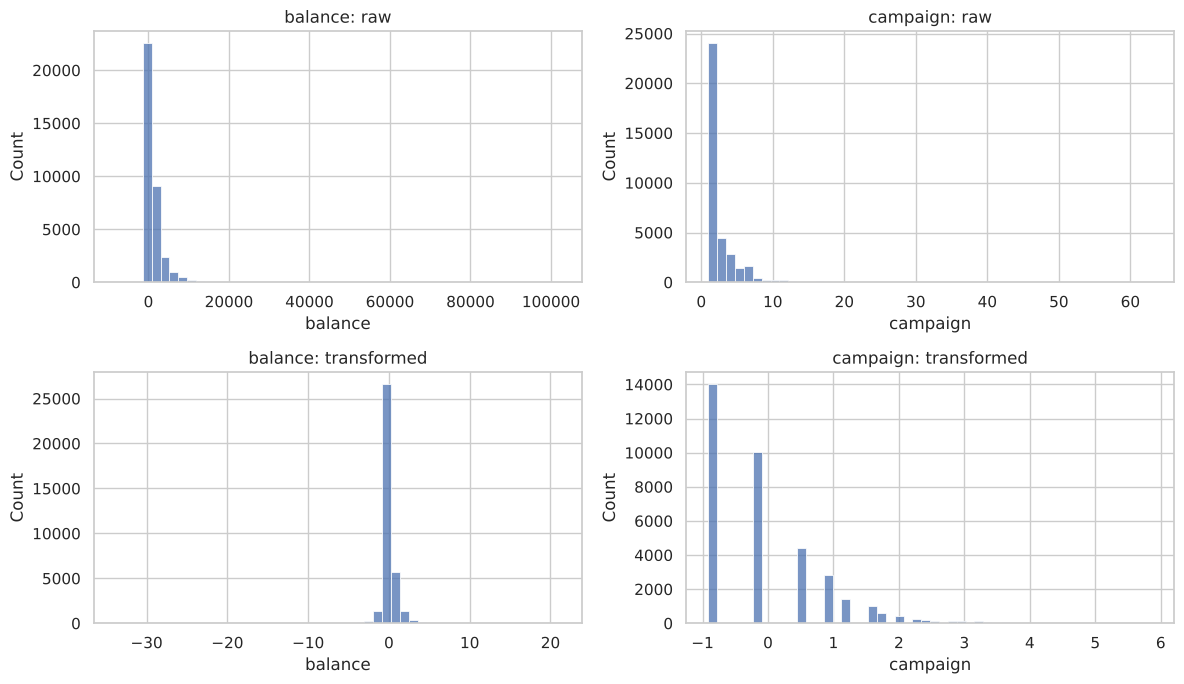

In [6]:
before = X_train[['balance', 'campaign']].skew()
after = Xl[['balance', 'campaign']].astype(float).skew()
print(pd.DataFrame({'skew_before': before, 'skew_after': after}).round(2))

fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for i, col in enumerate(['balance', 'campaign']):
    sns.histplot(X_train[col], bins=50, ax=axes[0, i]); axes[0, i].set_title(f'{col}: raw')
    sns.histplot(Xl[col].astype(float), bins=50, ax=axes[1, i]); axes[1, i].set_title(f'{col}: transformed')
plt.tight_layout(); plt.show()

## 4. Baseline: `DummyClassifier`

In [7]:
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import make_pipeline

baseline = make_pipeline(tree_preprocessor(), DummyClassifier(strategy='most_frequent')).fit(X_train, y_train)
proba = baseline.predict_proba(X_test)[:, 1]
save_result(evaluate('Baseline (always no)', y_test, proba))

,model,threshold,accuracy,balanced_accuracy,precision,recall,f1,roc_auc
0,Baseline (always no),0.5,0.883,0.5,0.0,0.0,0.0,0.5


The baseline is **88.3% accurate** while finding **zero** subscribers: balanced accuracy 0.50, recall 0, ROC-AUC 0.50.
Every model from here on is judged against these numbers, mainly on **ROC-AUC** (ranking quality) and **recall / F1** for the yes class.